<a href="https://colab.research.google.com/github/KlicperaV/Predstaveni_knihovny_Cartopy/blob/main/Cartopy_predstaveni_knihovny.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Cartopy**

[Cartopy](https://cartopy.readthedocs.io/stable/) je open-source knihovna určená především pro kartografickou vizualizaci prostorových dat a tvoření kvalitních mapových výstupů. Původně byla vyvinuta britskou meteorologickou službou *UK Met Office* pro rychlé a přesné zobrazení geografických dat.

Cartopy je postavena na knihovně *Matplotlib*, jejíž možnosti rozšiřuje geografickými souřadnicemi a kartografickými zobrazeními. Zároveň využívá další knihovny pro výpočet souřadnicových transformací (*PROJ*), numerické výpočty (*NumPy*) a práci s geometriemi (*Shapely*).

In [2]:
!pip install cartopy
!pip install OWSLib

import os
import json
from urllib.request import urlopen
from datetime import datetime, timezone
from glob import glob

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
import cartopy.io.img_tiles as cimgt
from cartopy import config
from cartopy.feature.nightshade import Nightshade
from owslib.wms import WebMapService

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 17.7 MB/s  0:00:00


# Kartografické projekce

Klasické osy z *Matplotlib* jsou rozšířeny o geografické funkce. Pomocí `cartopy.crs` lze definovat souřadnicový referenční systém a kartografické zobrazení výsledné mapy.

Přidáním elipsy zkreslení (*Tissotova indikatrix*) lze znázornit místní deformace při převodu zakřiveného povrchu do roviny mapy.

/usr/local/lib/python3.13/dist-packages/cartopy/mpl/geoaxes.py:792: UserWarning: Approximating coordinate system <Geographic 2D CRS: +proj=lonlat +datum=WGS84 +ellps=WGS84 +no_defs +t ...>
Name: unknown
Axis Info [ellipsoidal]:
- lon[east]: Longitude (degree)
- lat[north]: Latitude (degree)
Area of Use:
- undefined
Datum: World Geodetic System 1984
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich
 with the PlateCarree projection.
  warnings.warn(f'Approximating coordinate system {crs!r} with '
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


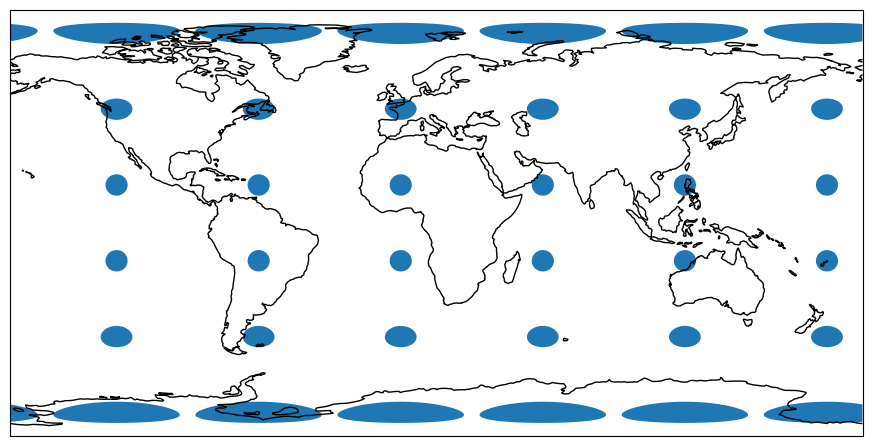

In [3]:
fig = plt.figure(figsize=(11, 8.5)) # Vytvoření prázdného grafu
ax = plt.subplot(projection=ccrs.PlateCarree(central_longitude=15)) # Rozšíření o geografii
ax.tissot() # Elipsy zkreslení
ax.coastlines() # Pobřeží

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


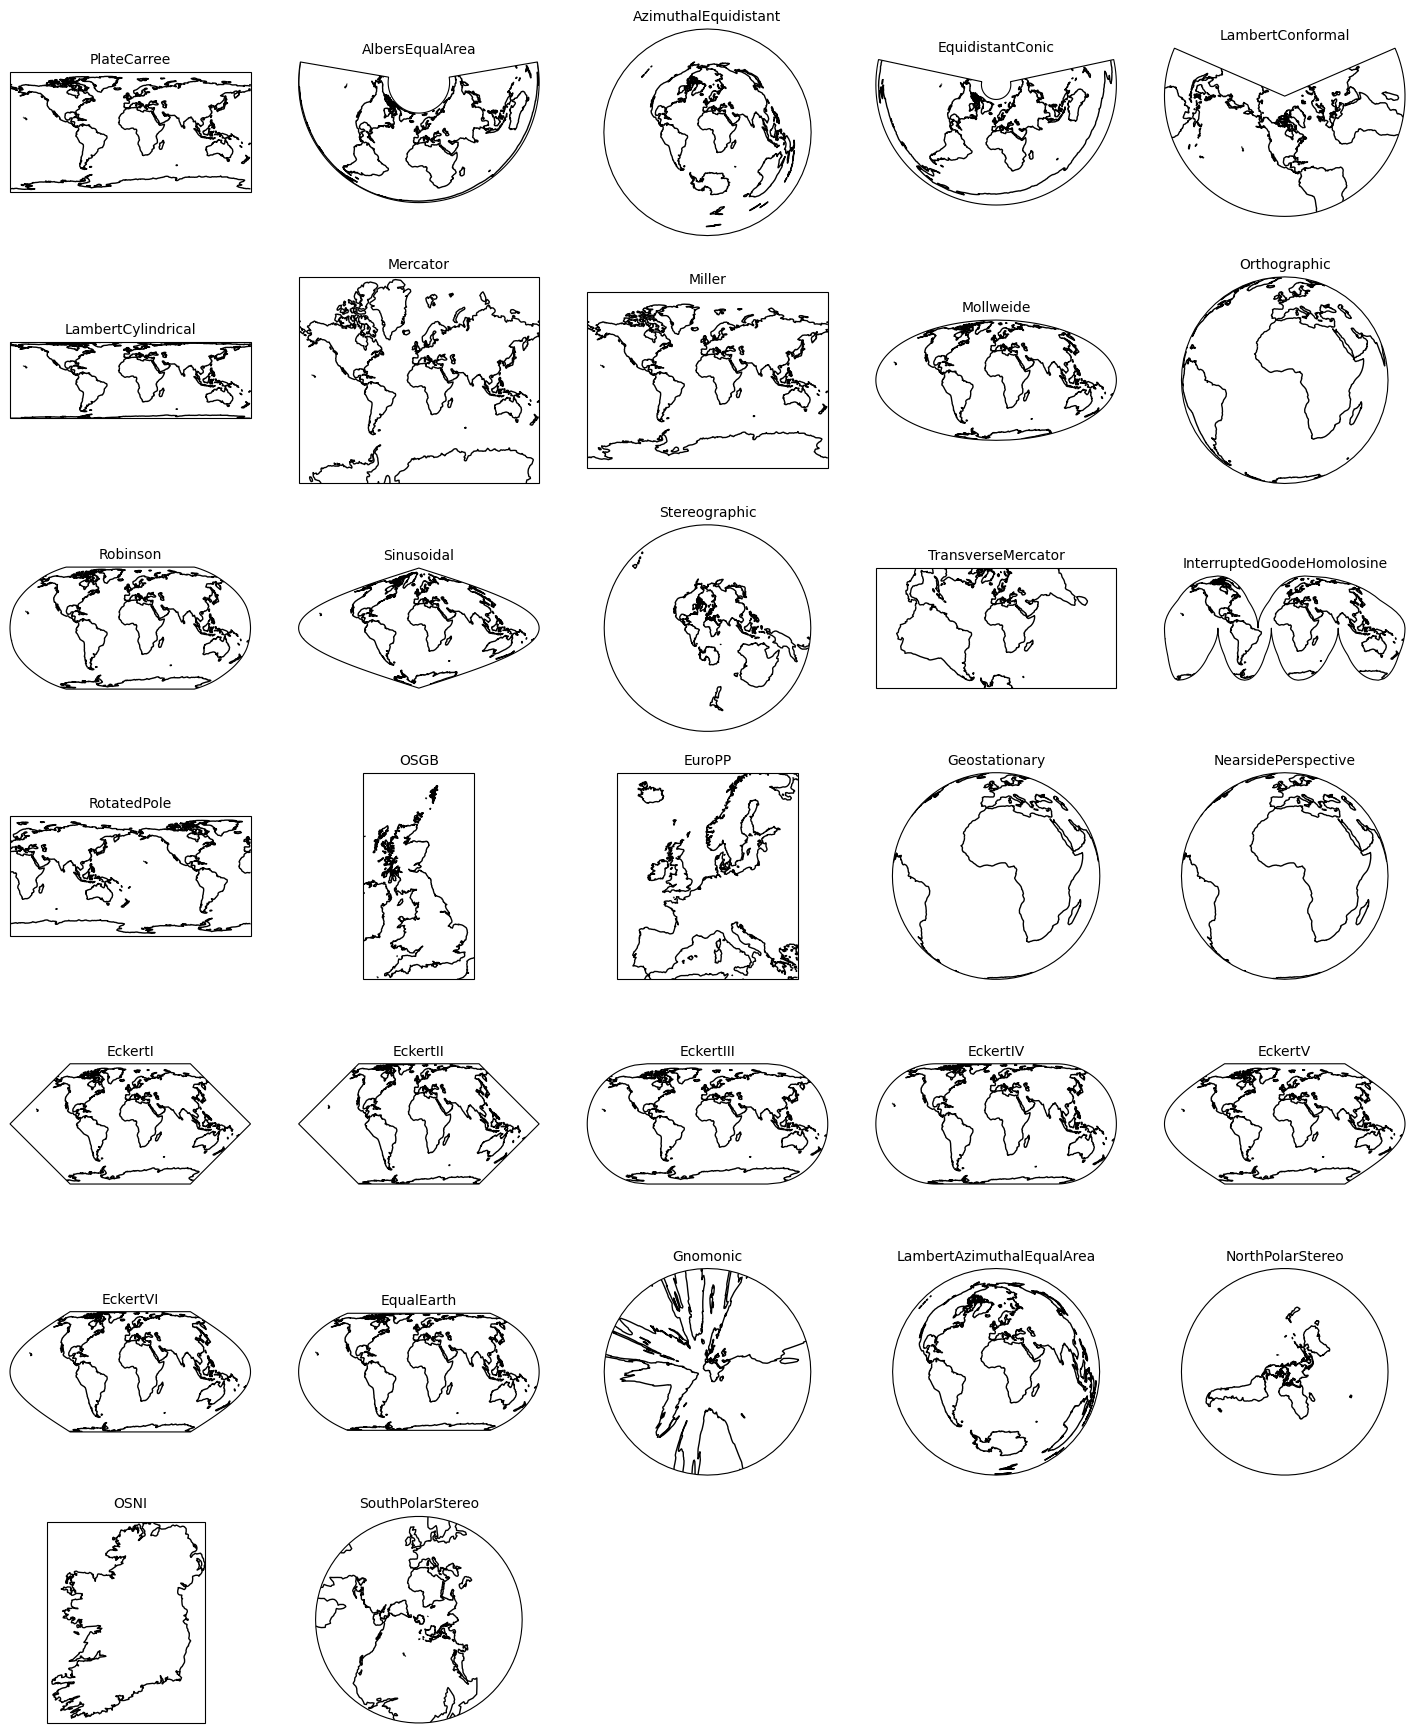

In [4]:

projections = [
    ccrs.PlateCarree(),
    ccrs.AlbersEqualArea(),
    ccrs.AzimuthalEquidistant(),
    ccrs.EquidistantConic(),
    ccrs.LambertConformal(),
    ccrs.LambertCylindrical(),
    ccrs.Mercator(),
    ccrs.Miller(),
    ccrs.Mollweide(),
    ccrs.Orthographic(),
    ccrs.Robinson(),
    ccrs.Sinusoidal(),
    ccrs.Stereographic(),
    ccrs.TransverseMercator(),
    ccrs.InterruptedGoodeHomolosine(),
    ccrs.RotatedPole(),
    ccrs.OSGB(),
    ccrs.EuroPP(),
    ccrs.Geostationary(),
    ccrs.NearsidePerspective(),
    ccrs.EckertI(),
    ccrs.EckertII(),
    ccrs.EckertIII(),
    ccrs.EckertIV(),
    ccrs.EckertV(),
    ccrs.EckertVI(),
    ccrs.EqualEarth(),
    ccrs.Gnomonic(),
    ccrs.LambertAzimuthalEqualArea(),
    ccrs.NorthPolarStereo(),
    ccrs.OSNI(),
    ccrs.SouthPolarStereo()
] # Seznam projekcí

fig = plt.figure(figsize=(18, 22))

for i, projection in enumerate(projections):

    ax = fig.add_subplot(7, 5, i + 1, projection=projection) # Cyklus pro vykreslení map
    ax.coastlines()
    ax.set_title(projection.__class__.__name__, fontsize=10) # Popisky


# Natural Earth

[Natural Earth](https://www.naturalearthdata.com/) je volně dostupná databáze geografických dat spravovaná dobrovolníky. Obsahuje vektorová a rastrová data celého světa, dostupná ve třech úrovních podrobnosti:

* **1 : 110 000 000**
* **1 : 50 000 000**
* **1 : 10 000 000**

A ve třech tématických kategoriích:

* **Geografická data**
* **Ekonomicko - Sociální data**
* **Rastrová data**

Cartopy umožňuje data z Natural Earth načítat a vykreslovat pomocí `cartopy.feature`. Potřebná data jsou automaticky stažena a uložena do mezipaměti.

Text(0.5, 1.0, 'Vrstvy Natural Earth')

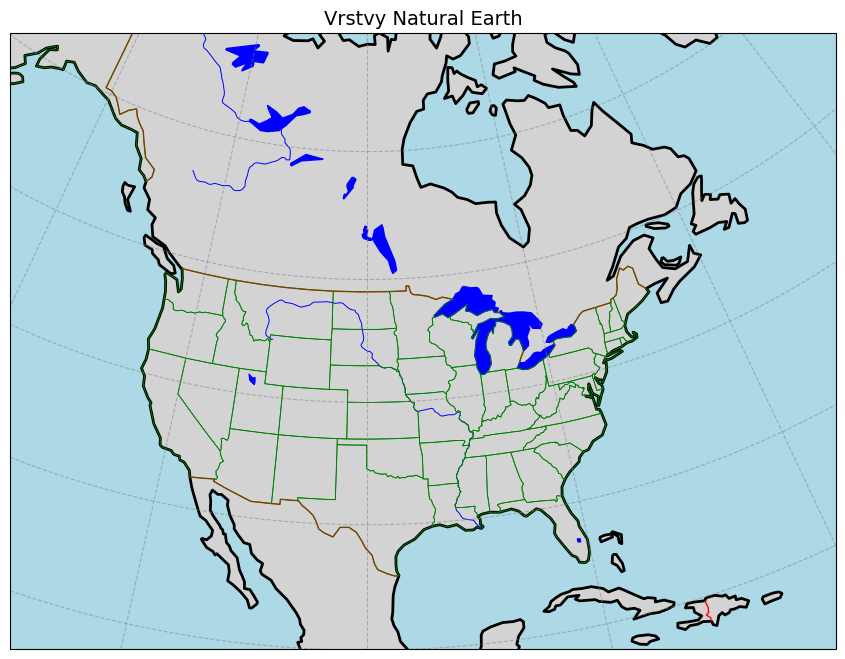

In [11]:

fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.LambertConformal(
    central_longitude=-100,
    central_latitude=40
))

ax.set_extent([-130, -60, 20, 65], crs=ccrs.PlateCarree()) # Nastavení rozsahu

# Základní geografické vrstvy Natural Earth

ax.add_feature(cfeature.LAND, facecolor="lightgray") # Pevnina

ax.add_feature(cfeature.OCEAN, facecolor="lightblue") # Oceán

ax.add_feature(cfeature.COASTLINE, edgecolor="black", linewidth=2) # Pobřeží

ax.add_feature(cfeature.BORDERS, edgecolor="red", linewidth=1) # Hranice

ax.add_feature(cfeature.LAKES, facecolor="blue", edgecolor="blue") # Jezera

ax.add_feature(cfeature.RIVERS, edgecolor="blue", linewidth=0.7) # Řeky

ax.add_feature(cfeature.STATES, edgecolor="green", linewidth=0.6) # Státy USA


ax.gridlines(linestyle="--", color="gray", alpha=0.5) # Zeměpisná síŤ


ax.set_title("Vrstvy Natural Earth",
             fontsize=14)


Mimo předdefinovaných dat lze z Natural Earth zobrazit libovolnou vrstvu na základě určení kategorie, jména a měřítka.

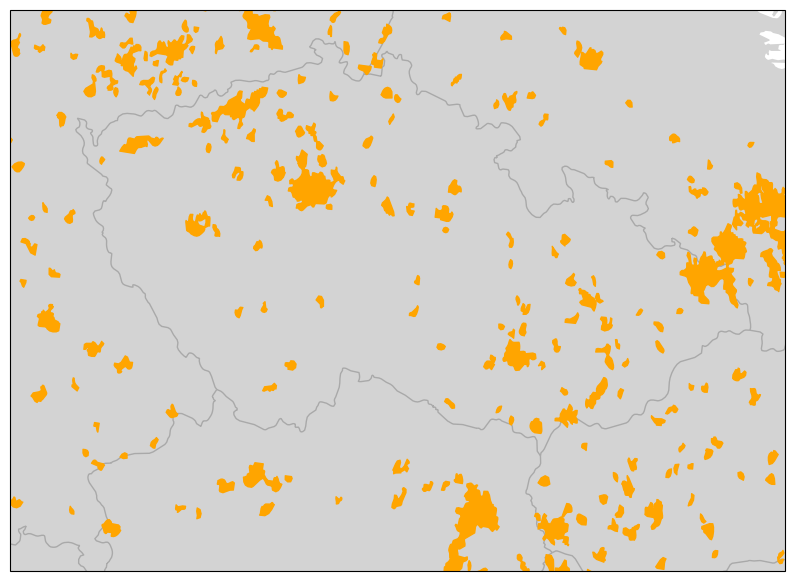

In [14]:
plt.figure(figsize=(10, 8))

projection = ccrs.epsg(5514) # ETRS89-LAEA
ax = plt.axes(projection=projection)

ax.set_extent([12, 19, 48, 51], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, edgecolor='darkgray', linewidth=1)

urban_areas = cfeature.NaturalEarthFeature(
  category='cultural',
  name='urban_areas',
  scale='10m',
  color = "orange"
    ) # Vrstva silně obydlených oblastí
ax.add_feature(urban_areas)


# Transformace

Pomocí `ax.set_extent` lze mapovému oknu nastavit geografický rozsah.

Parametr `transform` určuje souřadnicový systém vstupních dat. Přepočet probíhá automaticky.

Původní souřadnice Prahy:
Zeměpisná délka: 14.4208
Zeměpisná šířka: 50.088

Souřadnice v Mercatorově projekci:
X: 1605316.1128316394 m
Y: 6428736.333701613 m


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downlo

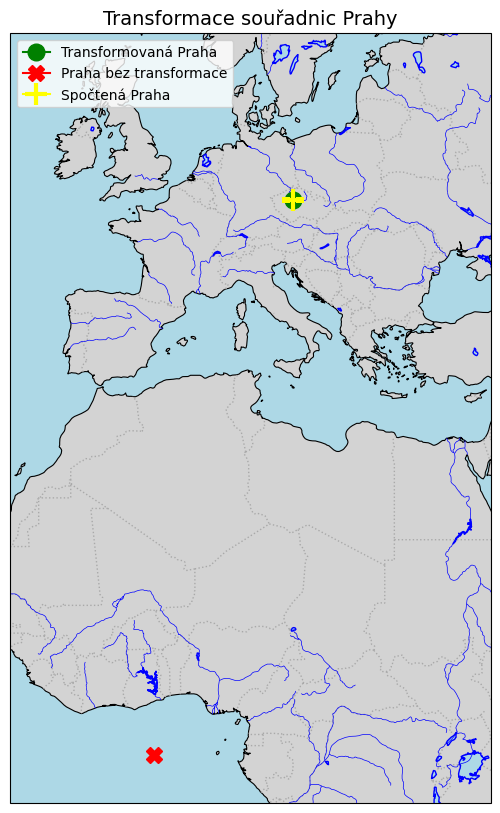

In [15]:

fig = plt.figure(figsize=(10, 10))

ax = plt.subplot(projection=ccrs.Mercator())

ax.set_extent([-15, 35, -5, 60], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='darkgray', linewidth=1)
ax.add_feature(cfeature.LAKES, facecolor='lightblue', edgecolor='blue')
ax.add_feature(cfeature.RIVERS, edgecolor='blue', linewidth=0.5)

lon, lat = 14.4208, 50.0880 # Souřadnice Prahy

ax.plot(lon, lat, marker='o', color='green', markersize=12,
        transform=ccrs.PlateCarree(),
        label='Transformovaná Praha') # Přepočet pomocí transform

ax.plot(lon, lat, marker='X', color='red', markersize=12,
        label='Praha bez transformace') # Vykreslení bez udání původní projekce


mercator = ccrs.Mercator()

x, y = mercator.transform_point(lon, lat, ccrs.PlateCarree()) # Přepočet pro výpis


print("Původní souřadnice Prahy:")
print("Zeměpisná délka:", lon)
print("Zeměpisná šířka:", lat)

print("\nSouřadnice v Mercatorově projekci:")
print("X:", x, "m")
print("Y:", y, "m")


ax.plot(x, y, marker='+', color='yellow', markersize=16,
        markeredgewidth=3,
        label='Spočtená Praha') # Stejný bod - "ruční" výpočet

ax.set_title('Transformace souřadnic Prahy', fontsize=14)
ax.legend(loc='upper left') # Legenda

* **Ortodroma**: Nejkratší spojnice dvou bodů na povrchu koule = `ccrs.Geodetic` vytváří body definované jako 3D souřadnice
* **Loxodroma**: Křivka protínající všechny poledníky pod stejným úhlem = `ccrs.Mercator` zobrazí jako přímku
* **Přímka v projekci**: Rovná spojnice bodů v rovině mapy, definovaná v souřadnicích zobrazení

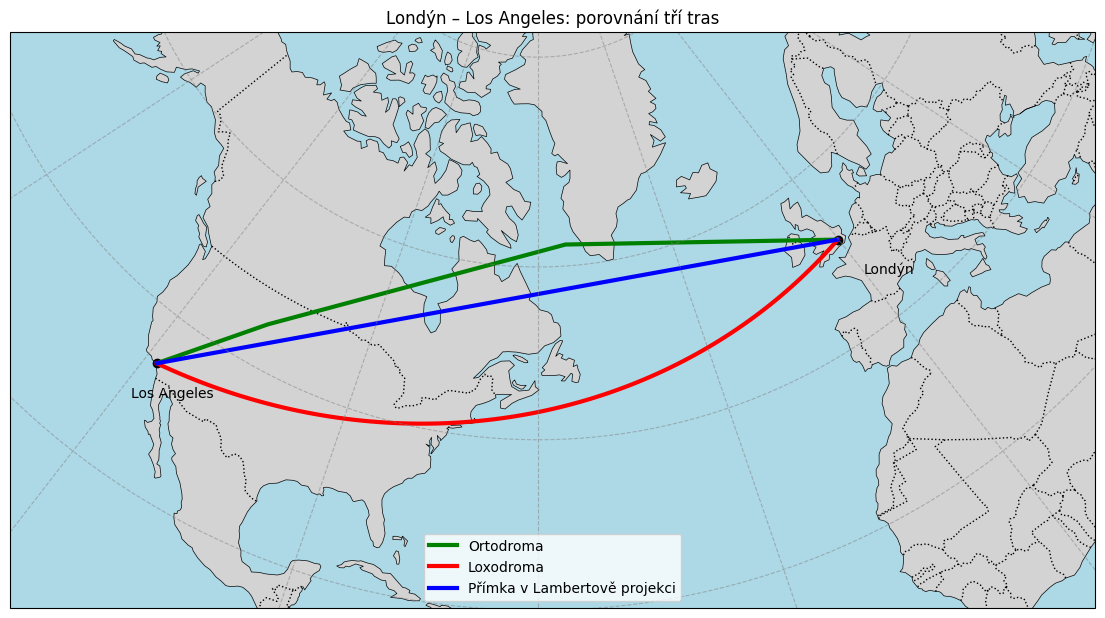

In [16]:


londyn = [-0.1276, 51.5074]
los_angeles = [-118.2437, 34.0522]

projekce = ccrs.LambertConformal(
    central_longitude=-60,
    central_latitude=45
)

fig = plt.figure(figsize=(14, 8))
ax = plt.axes(projection=projekce)

ax.set_extent([-130, 15, 20, 75], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linestyle=":")

ax.plot(londyn[0], londyn[1], "ko",
        transform=ccrs.PlateCarree())

ax.plot(los_angeles[0], los_angeles[1], "ko",
        transform=ccrs.PlateCarree())

ax.text(londyn[0], londyn[1] - 5, "Londýn",
        transform=ccrs.PlateCarree()) # Přídání popisku - add_text

ax.text(los_angeles[0], los_angeles[1] - 5, "Los Angeles",
        transform=ccrs.PlateCarree())

ax.plot(
    [londyn[0], los_angeles[0]],
    [londyn[1], los_angeles[1]],
    transform=ccrs.Geodetic(),
    color="green",
    linewidth=3,
    label="Ortodroma"
) # Ortodroma - nejkratší po povrchu Země

mercator = ccrs.Mercator()

x1, y1 = mercator.transform_point(
    londyn[0], londyn[1], ccrs.PlateCarree()
)

x2, y2 = mercator.transform_point(
    los_angeles[0], los_angeles[1], ccrs.PlateCarree()
) # Loxodroma - přímka v Mercatorovi

x = np.linspace(x1, x2, 100)
y = np.linspace(y1, y2, 100)

body = projekce.transform_points(mercator, x, y)

ax.plot(
    body[:, 0],
    body[:, 1],
    color="red",
    linewidth=3,
    label="Loxodroma"
)

x1, y1 = projekce.transform_point(
    londyn[0], londyn[1], ccrs.PlateCarree()
)

x2, y2 = projekce.transform_point(
    los_angeles[0], los_angeles[1], ccrs.PlateCarree()
)

ax.plot(
    [x1, x2],
    [y1, y2],
    color="blue",
    linewidth=3,
    label="Přímka v Lambertově projekci"
)

ax.gridlines(
    linestyle="--",
    color="gray",
    alpha=0.5
)

ax.set_title("Londýn – Los Angeles: porovnání tří tras")
ax.legend(loc="lower center")

# Rastrová data

Rastrová data lze vkládat několika způsoby. Rozdíl spočívá v tom, odkud data pocházejí a jak jsou načítána. V ukázce jsou využity tři funkce:

* `ax.imshow` - Zobrazení rastrových dat uložených v paměti
* `add_image` - Vložení rastrového podkladu složeného z dlaždic
* `add_wms` - Přidání mapového obrazu poskytovaného prostřednictvím WMS

Text(0.5, 1.0, 'Hurikán Miriam – satelitní snímek MODIS')

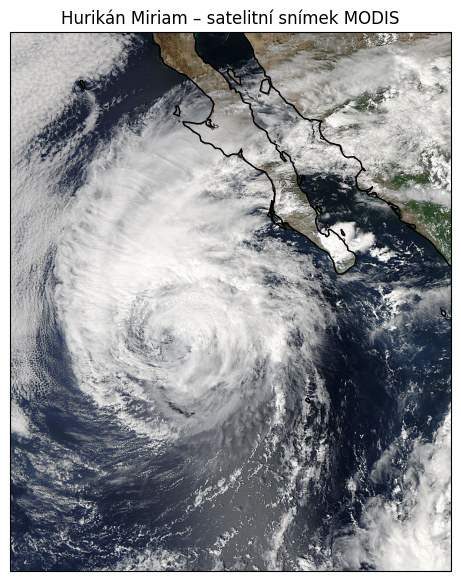

In [21]:

soubor = config["repo_data_dir"] / "raster" / "sample" / "Miriam.A2012270.2050.2km.jpg" # Určení cesty k datům

obrazek = plt.imread(soubor) # Načtení dat

rozsah = [-120.6766, -106.3210, 13.2301, 30.7669]


fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.imshow(
    obrazek,
    origin="upper",
    extent=rozsah,
    transform=ccrs.PlateCarree()
) # vykreslení obrázku

ax.coastlines(resolution="50m")

plt.title("Hurikán Miriam – satelitní snímek MODIS")

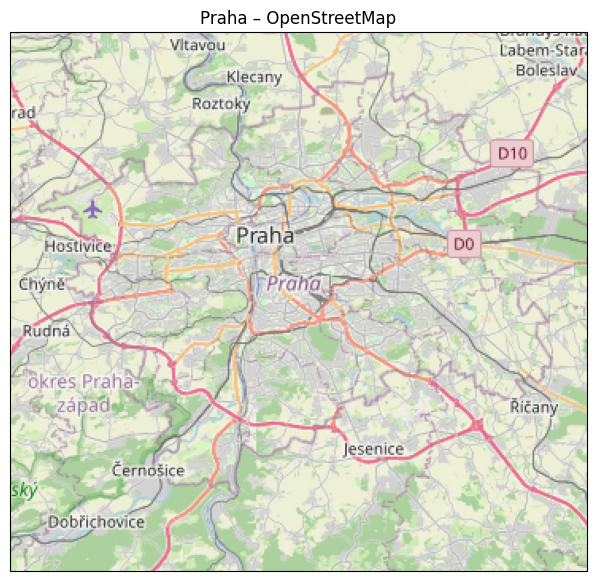

In [22]:


tiler = cimgt.OSM() # Zdroj dlaždic - Open street map


fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=tiler.crs)


ax.set_extent([14.2, 14.7, 49.9, 50.2], crs=ccrs.PlateCarree())

ax.add_image(tiler, 10) # Přidání dlaždice

plt.title("Praha – OpenStreetMap")
plt.show()

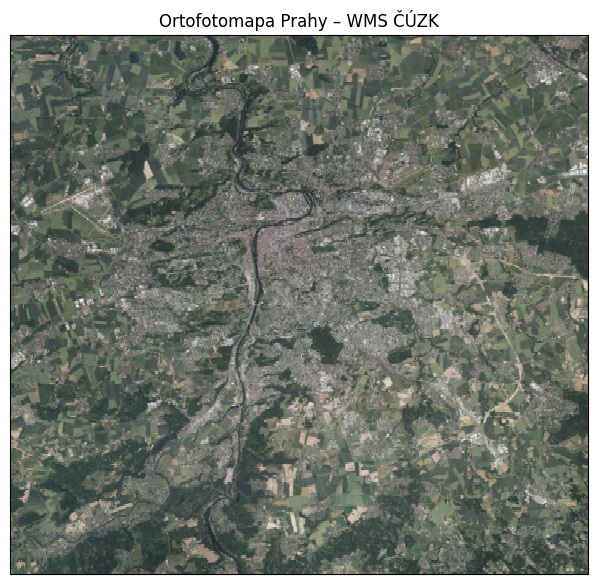

In [23]:


fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.Mercator())


ax.set_extent([14.2, 14.7, 49.9, 50.2], crs=ccrs.PlateCarree())

ax.add_wms(
    wms="https://ags.cuzk.gov.cz/arcgis1/services/ORTOFOTO/MapServer/WMSServer?",
    layers=["0"]
) # Připojení k ČUZK

plt.title("Ortofotomapa Prahy – WMS ČÚZK")
plt.show()

# Vektorová data

Pro možnost práce s jednotlivými objekty vektorových vrstev a jejich atributy je nutné jejich načtení ve formě shapefilu (.shp).

K tomuto účelu slouží `cartopy.io.shapereader`

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


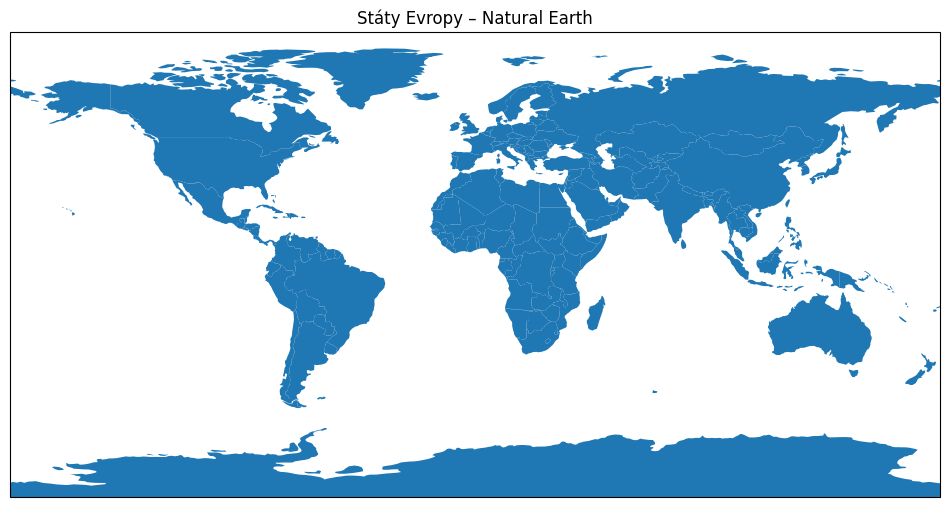

Prvních pět záznamů atributové tabulky:
{'featurecla': 'Admin-0 country', 'scalerank': 1, 'LABELRANK': 6, 'SOVEREIGNT': 'Fiji', 'SOV_A3': 'FJI', 'ADM0_DIF': 0, 'LEVEL': 2, 'TYPE': 'Sovereign country', 'TLC': '1', 'ADMIN': 'Fiji', 'ADM0_A3': 'FJI', 'GEOU_DIF': 0, 'GEOUNIT': 'Fiji', 'GU_A3': 'FJI', 'SU_DIF': 0, 'SUBUNIT': 'Fiji', 'SU_A3': 'FJI', 'BRK_DIFF': 0, 'NAME': 'Fiji', 'NAME_LONG': 'Fiji', 'BRK_A3': 'FJI', 'BRK_NAME': 'Fiji', 'BRK_GROUP': '', 'ABBREV': 'Fiji', 'POSTAL': 'FJ', 'FORMAL_EN': 'Republic of Fiji', 'FORMAL_FR': '', 'NAME_CIAWF': 'Fiji', 'NOTE_ADM0': '', 'NOTE_BRK': '', 'NAME_SORT': 'Fiji', 'NAME_ALT': '', 'MAPCOLOR7': 5, 'MAPCOLOR8': 1, 'MAPCOLOR9': 2, 'MAPCOLOR13': 2, 'POP_EST': 889953.0, 'POP_RANK': 11, 'POP_YEAR': 2019, 'GDP_MD': 5496, 'GDP_YEAR': 2019, 'ECONOMY': '6. Developing region', 'INCOME_GRP': '4. Lower middle income', 'FIPS_10': 'FJ', 'ISO_A2': 'FJ', 'ISO_A2_EH': 'FJ', 'ISO_A3': 'FJI', 'ISO_A3_EH': 'FJI', 'ISO_N3': '242', 'ISO_N3_EH': '242', 'UN_A3': '242', '

In [24]:


soubor = shpreader.natural_earth(
    resolution="110m",
    category="cultural",
    name="admin_0_countries"
) # Načtení shapefilu


reader = shpreader.Reader(soubor) # Otevření souboru
geometrie = reader.geometries() # Vytáhnutí geometrie

fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_geometries(geometrie, ccrs.PlateCarree()) # přidání polygonů do mapy


plt.title("Státy Evropy – Natural Earth")
plt.show()

print("Prvních pět záznamů atributové tabulky:")

for i, stat in enumerate(reader.records()):
    if i == 5:
        break
    print(stat.attributes) # Výpis z atributové tabulky

China 1397715000.0
India 1366417754.0
United States of America 328239523.0
Indonesia 270625568.0
Pakistan 216565318.0


Text(0.5, 1.0, 'Pět nejlidnatějších států světa')

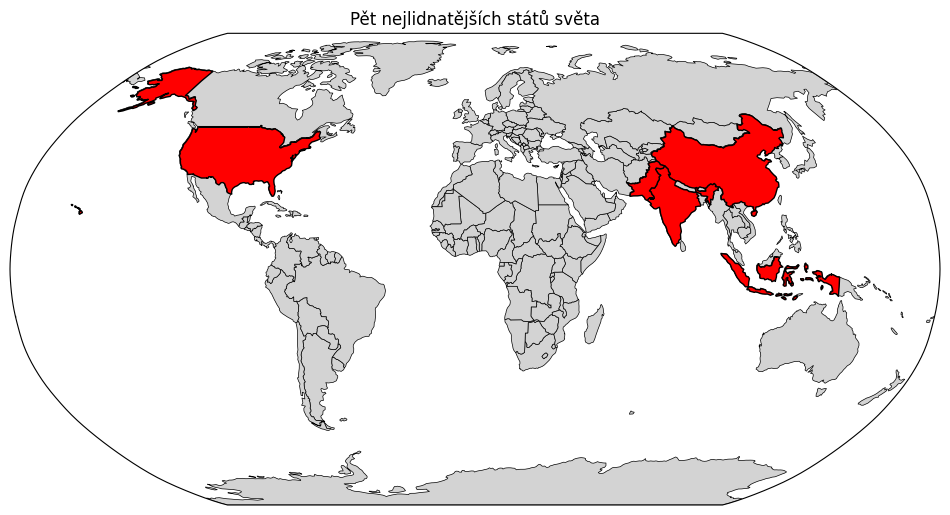

In [26]:
zaznamy = list(reader.records()) # Už jsme jednou načetly - pokračujeme v práci

serazene = sorted(
    zaznamy,
    key=lambda stat: stat.attributes["POP_EST"],
    reverse=True
) # Práce s atributovou tabulkou

top5 = serazene[:5]

for stat in top5:
    print(stat.attributes["NAME"], stat.attributes["POP_EST"]) # Výpis nejlidnatějších stítů

fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=ccrs.Robinson())

ax.add_geometries(
    reader.geometries(),
    ccrs.PlateCarree(),
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.5)

for stat in top5:
    ax.add_geometries(
        [stat.geometry],
        ccrs.PlateCarree(),
        facecolor="red",
        edgecolor="black"
    ) # Obarení na červeno

plt.title("Pět nejlidnatějších států světa")

Cartopy je v podstatě rozšíření knihovny Matplotlib. To umožňuje kombinaci klasického grafu s kartografickým výstupem.

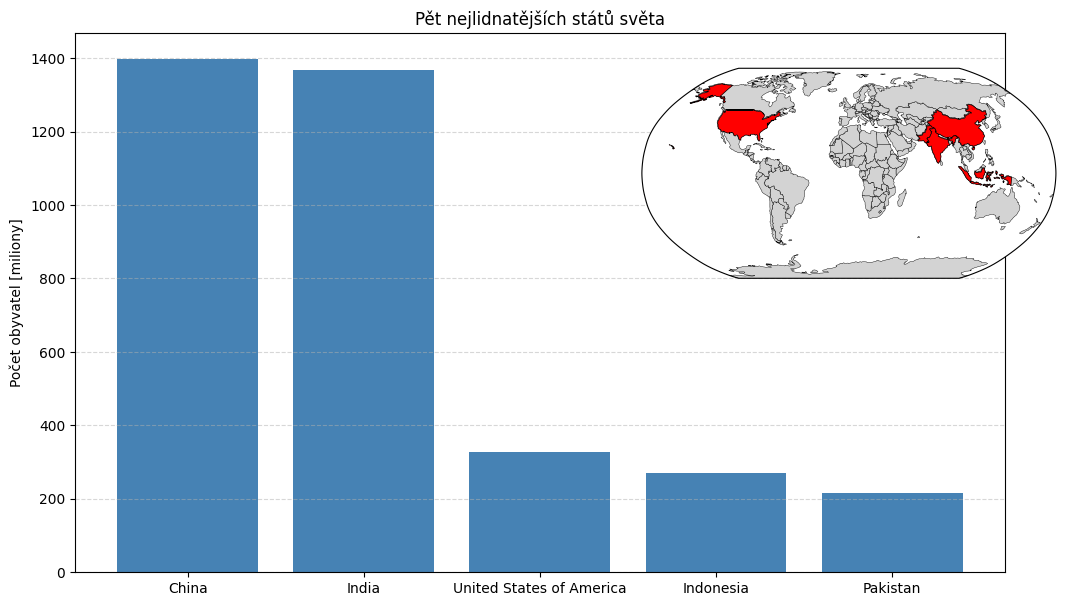

In [27]:

zaznamy = list(reader.records())

top5 = sorted(
    zaznamy,
    key=lambda stat: stat.attributes["POP_EST"],
    reverse=True
)[:5]

staty = [stat.attributes["NAME"] for stat in top5] # Vytažení názvu státu
populace = [stat.attributes["POP_EST"] / 1_000_000 for stat in top5] # Vytažení populace

fig = plt.figure(figsize=(12, 7))

# Sloupcový graf
ax = fig.add_subplot(111)

ax.bar(staty, populace, color="steelblue")
ax.set_ylabel("Počet obyvatel [miliony]")
ax.set_title("Pět nejlidnatějších států světa")
ax.grid(axis="y", linestyle="--", alpha=0.5)


mapa = fig.add_axes(
    [0.58, 0.53, 0.38, 0.30],
    projection=ccrs.Robinson()
) # Vložení mapy

mapa.add_geometries(
    reader.geometries(),
    ccrs.PlateCarree(),
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.3
)

for stat in top5:
    mapa.add_geometries(
        [stat.geometry],
        ccrs.PlateCarree(),
        facecolor="red",
        edgecolor="black",
        linewidth=0.5
    )

# Bonus

Na oficiálních stránkách Cartopy je dostupná [galerie](https://cartopy.readthedocs.io/stable/gallery/index.html) ukázkových mapových výstupů a jejich využití. Skripty následujících map pocházejí z tohoto zdroje.

**Animovaná mapa - časové řady**

In [28]:

fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.coastlines()

x = np.linspace(-80, 80)
xs, ys = np.meshgrid(2 * x + 180, x)
zs = xs + ys
vmin, vmax = np.min(zs), np.max(zs)
mesh = ax.pcolormesh(xs, ys, np.zeros_like(zs), transform=ccrs.PlateCarree(),
                     shading='auto', vmin=vmin, vmax=vmax)

n = 10

def update_mesh(t):
    mesh.set_array(zs.ravel() * t)

ts = [i / n for i in range(n)]
# Go back to the start to make it a smooth repeat
ts += ts[::-1]

ani = FuncAnimation(fig, update_mesh, frames=ts, interval=100)

# Close the figure so it doesn't display a duplicate static plot
plt.close(fig)

# Render the animation as an HTML5 video
HTML(ani.to_html5_video())

**Komplexní Batymetrická mapa**

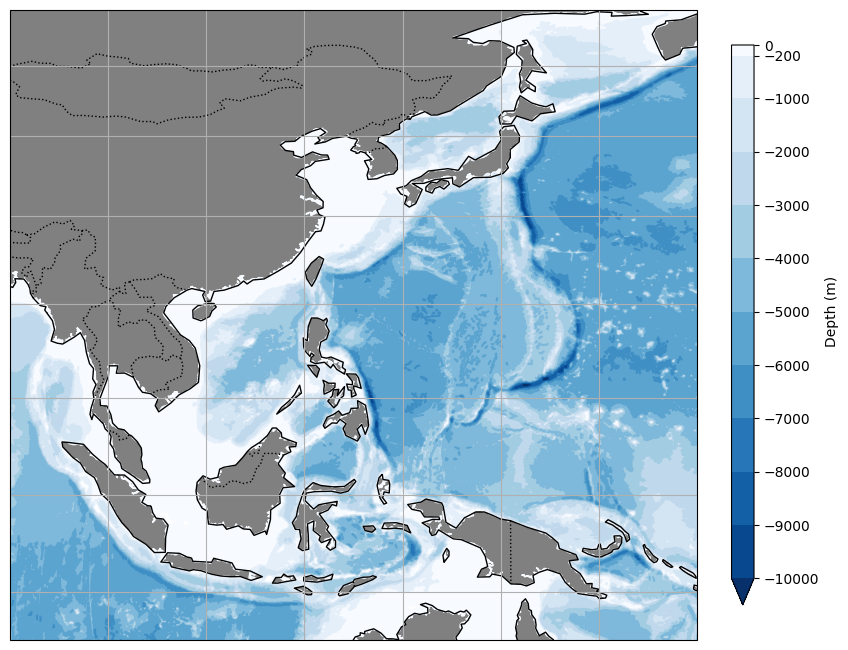

In [29]:

def load_bathymetry(zip_file_url):
    """Read zip file from Natural Earth containing bathymetry shapefiles"""
    # Download and extract shapefiles
    import io
    import zipfile

    import requests
    r = requests.get(zip_file_url)
    z = zipfile.ZipFile(io.BytesIO(r.content))
    z.extractall("ne_10m_bathymetry_all/")

    # Read shapefiles, sorted by depth
    shp_dict = {}
    files = glob('ne_10m_bathymetry_all/*.shp')
    assert len(files) > 0
    files.sort()
    depths = []
    for f in files:
        depth = '-' + f.split('_')[-1].split('.')[0]  # depth from file name
        depths.append(depth)
        bbox = (90, -15, 160, 60)  # (x0, y0, x1, y1)
        nei = shpreader.Reader(f, bbox=bbox)
        shp_dict[depth] = nei
    depths = np.array(depths)[::-1]  # sort from surface to bottom
    return depths, shp_dict


if __name__ == "__main__":
    # Load data (14.8 MB file)
    depths_str, shp_dict = load_bathymetry(
        'https://naturalearth.s3.amazonaws.com/' +
        '10m_physical/ne_10m_bathymetry_all.zip')

    # Construct a discrete colormap with colors corresponding to each depth
    depths = depths_str.astype(int)
    N = len(depths)
    nudge = 0.01  # shift bin edge slightly to include data
    boundaries = [min(depths)] + sorted(depths + nudge)  # low to high
    norm = matplotlib.colors.BoundaryNorm(boundaries, N)
    blues_cm = matplotlib.colormaps['Blues_r'].resampled(N)
    colors_depths = blues_cm(norm(depths))

    # Set up plot
    subplot_kw = {'projection': ccrs.LambertCylindrical()}
    fig, ax = plt.subplots(subplot_kw=subplot_kw, figsize=(9, 7))
    ax.set_extent([90, 160, -15, 60], crs=ccrs.PlateCarree())  # x0, x1, y0, y1

    # Iterate and plot feature for each depth level
    for i, depth_str in enumerate(depths_str):
        ax.add_geometries(shp_dict[depth_str].geometries(),
                          crs=ccrs.PlateCarree(),
                          color=colors_depths[i])

    # Add standard features
    ax.add_feature(cfeature.LAND, color='grey')
    ax.coastlines(lw=1, resolution='110m')
    ax.gridlines(draw_labels=False)
    ax.set_position([0.03, 0.05, 0.8, 0.9])

    # Add custom colorbar
    axi = fig.add_axes([0.85, 0.1, 0.025, 0.8])
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    sm = plt.cm.ScalarMappable(cmap=blues_cm, norm=norm)
    fig.colorbar(mappable=sm,
                 cax=axi,
                 spacing='proportional',
                 extend='min',
                 ticks=depths,
                 label='Depth (m)')

    # Convert vector bathymetries to raster (saves a lot of disk space)
    # while leaving labels as vectors
    ax.set_rasterized(True)

**Předpověď výskytu polární záře**

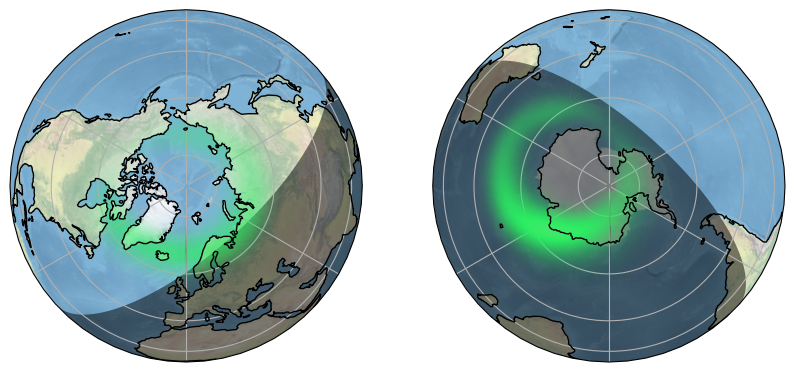

In [30]:

def aurora_forecast():
    """
    Get the latest Aurora Forecast from https://www.swpc.noaa.gov.

    Returns
    -------
    img : numpy array
        The pixels of the image in a numpy array.
    img_proj : cartopy CRS
        The rectangular coordinate system of the image.
    img_extent : tuple of floats
        The extent of the image ``(x0, y0, x1, y1)`` referenced in
        the ``img_proj`` coordinate system.
    origin : str
        The origin of the image to be passed through to matplotlib's imshow.
    dt : datetime
        Time of forecast validity.

    """

    # GitHub gist to download the example data from
    url = ('https://gist.githubusercontent.com/lgolston/594c030876c0614d3'
           '6d13d03e4f115b6/raw/342ff751419204594180e88d69b3986dbd4fea4a/'
           'ovation_aurora_latest.json')
    # To plot the current forecast instead, uncomment the following line
    # url = 'https://services.swpc.noaa.gov/json/ovation_aurora_latest.json'

    # load data (JSON format)
    response = urlopen(url)
    aurora = json.loads(response.read().decode('utf-8'))
    # parse timestamp
    dt = datetime.strptime(aurora['Forecast Time'], '%Y-%m-%dT%H:%M:%SZ')
    # convert lists of [lon, lat, value] to 2D array of probability values
    aurora_data = np.array(aurora['coordinates'])
    img = np.reshape(aurora_data[:, 2], (181, 360), order='F')

    img_proj = ccrs.PlateCarree()
    img_extent = (0, 359, -90, 90)
    return img, img_proj, img_extent, 'lower', dt


def aurora_cmap():
    """Return a colormap with aurora like colors"""
    stops = {'red': [(0.00, 0.1725, 0.1725),
                     (0.50, 0.1725, 0.1725),
                     (1.00, 0.8353, 0.8353)],

             'green': [(0.00, 0.9294, 0.9294),
                       (0.50, 0.9294, 0.9294),
                       (1.00, 0.8235, 0.8235)],

             'blue': [(0.00, 0.3843, 0.3843),
                      (0.50, 0.3843, 0.3843),
                      (1.00, 0.6549, 0.6549)],

             'alpha': [(0.00, 0.0, 0.0),
                       (0.50, 1.0, 1.0),
                       (1.00, 1.0, 1.0)]}

    return LinearSegmentedColormap('aurora', stops)


def main():
    fig = plt.figure(figsize=[10, 5])

    # We choose to plot in an Orthographic projection as it looks natural
    # and the distortion is relatively small around the poles where
    # the aurora is most likely.

    # ax1 for Northern Hemisphere
    ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.Orthographic(0, 90))

    # ax2 for Southern Hemisphere
    ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.Orthographic(180, -90))

    img, crs, extent, origin, dt = aurora_forecast()

    for ax in [ax1, ax2]:
        ax.coastlines(zorder=3)
        ax.stock_img()
        ax.gridlines()
        ax.add_feature(Nightshade(dt))
        ax.imshow(img, vmin=0, vmax=100, transform=crs,
                  extent=extent, origin=origin, zorder=2,
                  cmap=aurora_cmap())

    plt.show()


if __name__ == '__main__':
    main()